In [413]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report,confusion_matrix,accuracy_score
import warnings
warnings.filterwarnings("ignore")

In [414]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from sklearn.linear_model import Perceptron

In [415]:
df=pd.read_csv("iris.csv")
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [416]:
df["species"].value_counts()

,count
species,
setosa,50
versicolor,50
virginica,50


In [417]:
X=df.drop("species",axis=1)
y=df["species"]

In [418]:
#Convert y values into(0,1,2)
encoder=LabelEncoder()
y_int=encoder.fit_transform(y)

In [419]:
y_int

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [420]:
X_train,X_test,y_train,y_test=train_test_split(X,y_int,test_size=0.2,random_state=42,stratify=y_int)

In [421]:
#For bringing values in same range
scaler=StandardScaler()
X_train_scaled=scaler.fit_transform(X_train)
X_test_scaled=scaler.fit_transform(X_test)

#Perceptron Model

In [422]:
per=Perceptron(max_iter=1000,random_state=42)
per.fit(X_train_scaled,y_train)

Perceptron(random_state=42)

In [423]:
y_pred=per.predict(X_test_scaled)

In [424]:
accuracy_score(y_test,y_pred)

0.8666666666666667

In [425]:
print(classification_report(y_test,y_pred))

              precision    recall  f1-score   support

           0       0.83      1.00      0.91        10
           1       0.88      0.70      0.78        10
           2       0.90      0.90      0.90        10

    accuracy                           0.87        30
   macro avg       0.87      0.87      0.86        30
weighted avg       0.87      0.87      0.86        30



#ANN Model

In [426]:
model=keras.Sequential([
    layers.Input(shape=(X_train.shape[1],)),
    layers.Dense(8,activation="relu"),
    layers.Dense(3,activation="softmax")
])

In [427]:
model.compile(optimizer="adam",loss="sparse_categorical_crossentropy",metrics=["accuracy"])

In [428]:
history = model.fit(
    X_train_scaled, y_train,
    validation_data=(X_test_scaled, y_test),
    epochs=100,
    batch_size=8,
    verbose=1
)

Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - accuracy: 0.5250 - loss: 1.1293 - val_accuracy: 0.4333 - val_loss: 1.0539
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5333 - loss: 1.0376 - val_accuracy: 0.4333 - val_loss: 0.9722
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.5750 - loss: 0.9583 - val_accuracy: 0.5667 - val_loss: 0.8994
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5667 - loss: 0.8913 - val_accuracy: 0.6000 - val_loss: 0.8358
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6250 - loss: 0.8268 - val_accuracy: 0.7000 - val_loss: 0.7837
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7083 - loss: 0.7740 - val_accuracy: 0.7000 - val_loss: 0.7370
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7250 - loss: 0.7257 - val_accuracy: 0.7000 - val_loss: 0.6979
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7333 - loss: 0.6854 - val_accuracy: 0.7333 - 

In [429]:
loss, acc = model.evaluate(X_test_scaled, y_test, verbose=0)
print(acc)

0.8999999761581421


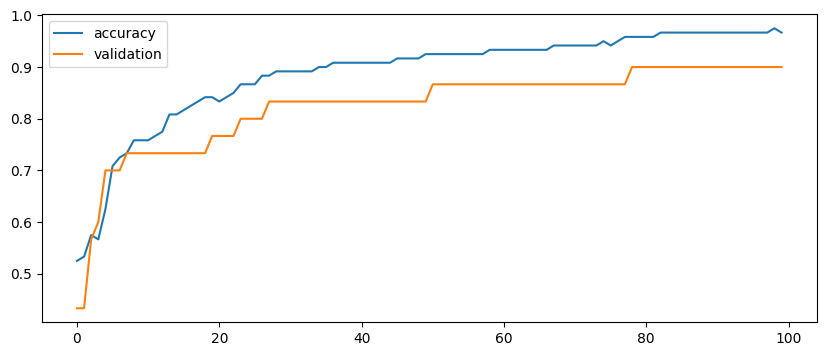

In [430]:
plt.figure(figsize=(10,4))
plt.plot(history.history["accuracy"], label="accuracy")
plt.plot(history.history["val_accuracy"], label="validation")
plt.legend()

In [431]:
y_pred_ann = np.argmax(model.predict(X_test_scaled, verbose=0), axis=1)
print(classification_report(y_test, y_pred_ann, target_names=encoder.classes_))
print("Perceptron:", accuracy_score(y_test, per.predict(X_test_scaled)))
print("ANN:", accuracy_score(y_test, y_pred_ann))

              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        10
  versicolor       0.89      0.80      0.84        10
   virginica       0.82      0.90      0.86        10

    accuracy                           0.90        30
   macro avg       0.90      0.90      0.90        30
weighted avg       0.90      0.90      0.90        30

Perceptron: 0.8666666666666667
ANN: 0.9
